# Lab 2 — Anomaly Detection for Cybersecurity Logs

**Group submission (three students)** — Isolation Forest vs. Autoencoder with Categorical Embeddings  
**Main deliverable:** one executed Jupyter notebook containing the provided model workflow, saved outputs, visualizations, evidence-based disagreement analysis, and final conclusions.

The model/data-generation design is based on the instructor-provided `AnomalyDetectionComparison.ipynb` from [HIT-ai-cybersecurity-labs](https://github.com/melofon/HIT-ai-cybersecurity-labs/tree/main/labs/lab2%20Anomaly%20Detection/work). We preserve the original synthetic login scenario and modeling method; our additions are reproducibility seeding, explicit EDA checks, clearer visual explanations, detailed SOC triage, and written conclusions.

**Reproduce:** In JupyterLab with NumPy, pandas, scikit-learn, Matplotlib, Keras 3, and PyTorch installed, choose **Kernel → Restart Kernel and Run All Cells**. The dataset is generated locally in this notebook; no external CSV is needed. In the instructor's repository, `docker compose up --build` supplies the environment.

In [1]:
import os
os.environ["KERAS_BACKEND"] = "torch"

import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from keras import layers
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import IsolationForest
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, precision_recall_fscore_support
from sklearn.decomposition import PCA
from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)  # extra reproducibility fix for Keras/Torch
print('Keras:', keras.__version__, '| Backend:', keras.backend.backend(), '| Seed:', SEED)

Keras: 3.13.2 | Backend: torch | Seed: 42


## 1. Synthetic dataset and threat scenario
The provided synthetic generator models normal login telemetry alongside a minority of overtly anomalous events. Attack events combine unknown countries/devices, unusual hours, elevated login failures, geographic distance, and greater outgoing traffic. These features can be relevant to MITRE ATT&CK **T1078 (Valid Accounts)** and **T1110 (Brute Force)** when independent contextual evidence supports those behaviors. The synthetic label is used for evaluation, not as a model input.

In [2]:
N_NORMAL, N_ATTACK = 3800, 160
users = ["analyst01", "analyst02", "finance01", "developer01", "admin01"]
usual_country = {name: "IL" for name in users}
usual_device = {
    "analyst01": "managed_laptop",
    "analyst02": "managed_laptop",
    "finance01": "managed_laptop",
    "developer01": "developer_workstation",
    "admin01": "admin_workstation",
}
rows = []
for _ in range(N_NORMAL):
    user = np.random.choice(users, p=[0.25, 0.20, 0.20, 0.25, 0.10])
    rows.append({
        "user": user,
        "country": usual_country[user],
        "device": usual_device[user],
        "protocol": np.random.choice(["HTTPS", "VPN", "SSH"], p=[0.60, 0.32, 0.08]),
        "hour": int(np.clip(np.random.normal(12.5, 2.5), 6, 21)),
        "failed_attempts": np.random.poisson(0.25),
        "distance_km": abs(np.random.normal(8, 12)),
        "session_minutes": max(1, np.random.gamma(3.5, 12)),
        "bytes_out_mb": max(0.1, np.random.lognormal(2.0, 0.6)),
        "is_attack": 0,
    })
for _ in range(N_ATTACK):
    user = np.random.choice(users)
    rows.append({
        "user": user,
        "country": np.random.choice(["RU", "CN", "SG", "US", "DE"]),
        "device": np.random.choice(["unknown", "mobile", "unmanaged_laptop"]),
        "protocol": np.random.choice(["HTTPS", "VPN", "SSH"]),
        "hour": np.random.choice([0, 1, 2, 3, 4, 23]),
        "failed_attempts": np.random.randint(5, 18),
        "distance_km": np.random.uniform(800, 9000),
        "session_minutes": np.random.uniform(1, 20),
        "bytes_out_mb": np.random.lognormal(5.0, 0.7),
        "is_attack": 1,
    })
df = pd.DataFrame(rows).sample(frac=1, random_state=SEED).reset_index(drop=True)
display(df.head())
print('Shape:', df.shape)
print('Class distribution:\n', df['is_attack'].value_counts().sort_index())

,user,country,device,protocol,hour,failed_attempts,distance_km,session_minutes,bytes_out_mb,is_attack
0,developer01,IL,developer_workstation,HTTPS,14,1,13.948183,115.895930,7.137972,0
1,analyst01,IL,managed_laptop,HTTPS,16,0,20.547952,54.179346,10.660855,0
2,analyst02,IL,managed_laptop,HTTPS,15,0,28.135590,40.337349,5.276849,0
3,analyst02,IL,managed_laptop,HTTPS,17,1,14.747003,56.774082,4.102999,0
4,finance01,IL,managed_laptop,VPN,10,1,14.617715,45.746867,20.057241,0


Shape: (3960, 10)
Class distribution:
 is_attack
0    3800
1     160
Name: count, dtype: int64


## 2. Exploratory data analysis (EDA)

The dataset contains four categorical attributes (`user`, `country`, `device`, `protocol`), five numeric telemetry features (including `hour`), and a separate ground-truth label. We inspect data types, missing and infinite values, normal-vs-attack medians, and visual distributions before modeling.

Dtypes:
 user                object
country             object
device              object
protocol            object
hour                 int64
failed_attempts      int64
distance_km        float64
session_minutes    float64
bytes_out_mb       float64
is_attack            int64
Missing values: 0
Infinite numeric values: 0
Class percentages:
 is_attack
0    95.96
1     4.04
Name: proportion, dtype: float64
Median numerical features by ground truth:
 is_attack            0        1
hour             12.00     2.00
failed_attempts   0.00    11.00
distance_km      10.03  4408.58
session_minutes  37.99     9.48
bytes_out_mb      7.47   149.09


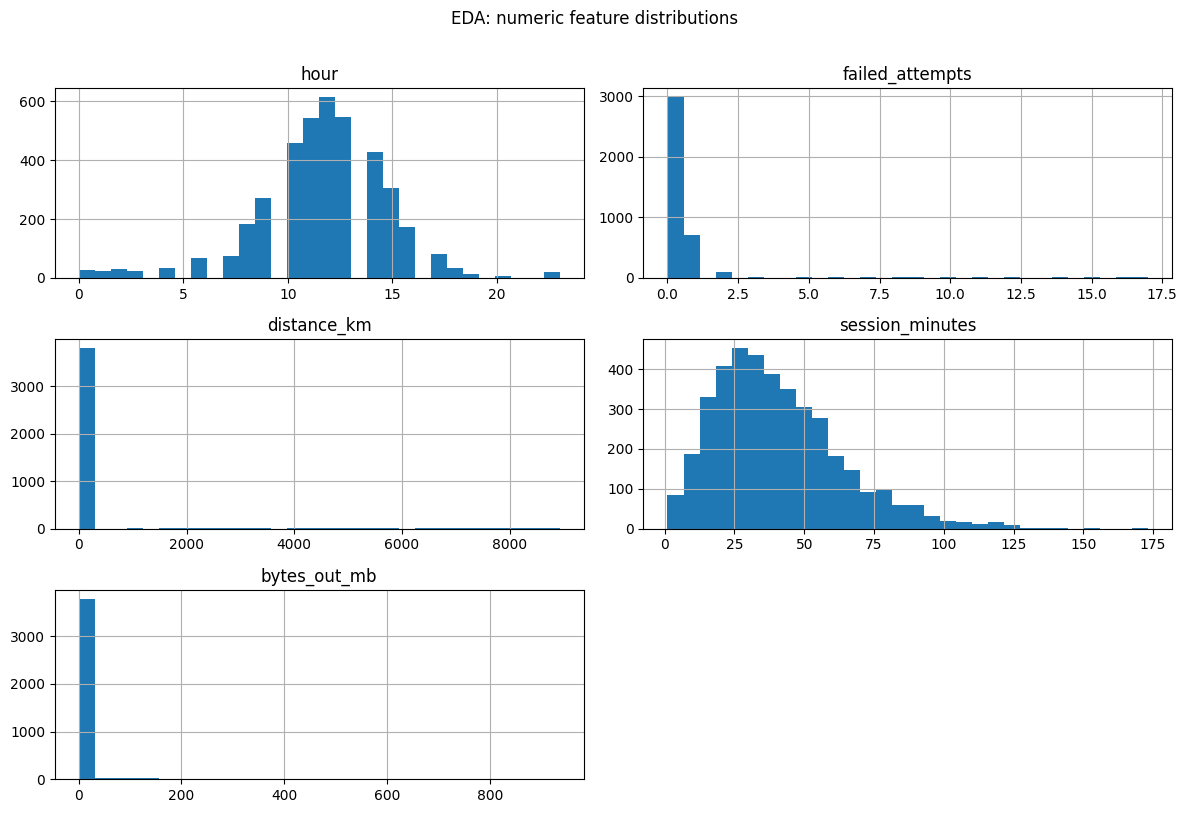

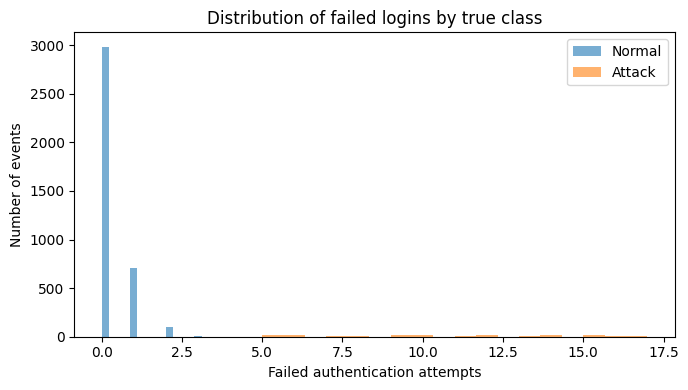

In [3]:
numeric_cols = ['hour', 'failed_attempts', 'distance_km', 'session_minutes', 'bytes_out_mb']
categorical_cols = ['user', 'country', 'device', 'protocol']
print('Dtypes:\n', df.dtypes.to_string())
print('Missing values:', int(df.isna().sum().sum()))
print('Infinite numeric values:', int(np.isinf(df[numeric_cols].to_numpy(dtype=float)).sum()))
print('Class percentages:\n', (df['is_attack'].value_counts(normalize=True).sort_index()*100).round(2))
print('Median numerical features by ground truth:\n', df.groupby('is_attack')[numeric_cols].median().T.round(2))
ax = df[numeric_cols].hist(figsize=(12, 8), bins=30)
plt.suptitle('EDA: numeric feature distributions', y=1.01)
plt.tight_layout()
plt.show()
plt.figure(figsize=(7, 4))
for label, frame in df.groupby('is_attack'):
    plt.hist(frame['failed_attempts'], bins=18, alpha=0.6, label=('Attack' if label else 'Normal'))
plt.xlabel('Failed authentication attempts')
plt.ylabel('Number of events')
plt.title('Distribution of failed logins by true class')
plt.legend()
plt.tight_layout()
plt.show()

**EDA interpretation.** Attacks were deliberately generated with high failed-login counts, large travel distances, unfamiliar devices/countries and elevated outgoing traffic. Thus the synthetic distinction is unusually clear, and evaluation scores may be optimistic relative to real SOC telemetry. Normal employees can sometimes travel, use remote access, or transfer data legitimately, so anomalies still require context. No missing/infinite numeric values should be present in the constructed dataset.

## 3. Stratified train, validation, and test partitions

The autoencoder is trained only on **normal** training events. Labels are retained for evaluation and for describing the synthetic attack prevalence; the Isolation Forest baseline uses the original mixed training partition and its prevalence-derived contamination setting. This difference in training conditions is a limitation when comparing them.

In [4]:
train_df, temp_df = train_test_split(df, test_size=0.40, stratify=df['is_attack'], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df['is_attack'], random_state=SEED)
normal_train_df = train_df[train_df['is_attack'] == 0].copy()
normal_val_df = val_df[val_df['is_attack'] == 0].copy()
print('Train:', train_df.shape, '| Normal-only AE train:', normal_train_df.shape)
print('Validation:', val_df.shape, '| Test:', test_df.shape)
print('Test labels:\n', test_df['is_attack'].value_counts().sort_index())

Train: (2376, 10) | Normal-only AE train: (2280, 10)
Validation: (792, 10) | Test: (792, 10)
Test labels:
 is_attack
0    760
1     32
Name: count, dtype: int64


## 4. Model A — Isolation Forest
Numeric inputs are standardized; categorical fields are one-hot encoded. Isolation Forest assigns higher outlier scores to records that can be isolated in relatively few tree partitions. The contamination parameter equals the attack share of the mixed training partition, as in the provided notebook.

In [5]:
if_preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), numeric_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols),
])
X_if_train = if_preprocessor.fit_transform(train_df[numeric_cols + categorical_cols])
X_if_test = if_preprocessor.transform(test_df[numeric_cols + categorical_cols])
y_test = test_df['is_attack'].to_numpy()
iso = IsolationForest(n_estimators=300, contamination=float(train_df['is_attack'].mean()), random_state=SEED, n_jobs=-1)
iso.fit(X_if_train)
if_score = -iso.decision_function(X_if_test)
if_pred = (iso.predict(X_if_test) == -1).astype(int)
print('Isolation Forest confusion matrix [TN, FP; FN, TP]:\n', confusion_matrix(y_test, if_pred))
print(classification_report(y_test, if_pred, target_names=['Normal','Attack']))

Isolation Forest confusion matrix [TN, FP; FN, TP]:
 [[759   1]
 [  0  32]]
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00       760
      Attack       0.97      1.00      0.98        32

    accuracy                           1.00       792
   macro avg       0.98      1.00      0.99       792
weighted avg       1.00      1.00      1.00       792



## 5. Model B — Autoencoder with trainable categorical embeddings
Numeric features are standardized based on normal-only training data; category tokens are encoded and embedded. An eight-dimensional latent representation reconstructs both numeric and categorical outputs. A high weighted reconstruction error indicates that the event differs from learned normal behavior.

In [6]:
num_scaler = StandardScaler().fit(normal_train_df[numeric_cols])
category_maps, category_sizes = {}, {}
for col in categorical_cols:
    values = sorted(train_df[col].astype(str).unique().tolist())
    category_maps[col] = {value:i+1 for i,value in enumerate(values)}  # 0: unknown
    category_sizes[col] = len(values) + 1

def prepare_ae_frame(frame):
    numeric = num_scaler.transform(frame[numeric_cols]).astype('float32')
    inputs = {'numeric': numeric}
    targets = {'numeric_out': numeric}
    for col in categorical_cols:
        indices = frame[col].astype(str).map(category_maps[col]).fillna(0).astype('int32').to_numpy()
        inputs[col] = indices
        targets[f'{col}_out'] = indices
    return inputs, targets

ae_train_inputs, ae_train_targets = prepare_ae_frame(normal_train_df)
ae_val_inputs, ae_val_targets = prepare_ae_frame(normal_val_df)
ae_test_inputs, ae_test_targets = prepare_ae_frame(test_df)

In [7]:
numeric_input = layers.Input(shape=(len(numeric_cols),), name='numeric')
model_inputs = {'numeric': numeric_input}
parts = [numeric_input]
for col in categorical_cols:
    inp = layers.Input(shape=(), dtype='int32', name=col)
    model_inputs[col] = inp
    emb_dim = min(8, max(2, int(np.ceil(np.sqrt(category_sizes[col])))))
    emb = layers.Embedding(category_sizes[col], emb_dim, name=f'{col}_embedding')(inp)
    parts.append(layers.Flatten()(emb))
combined = layers.Concatenate(name='combined_features')(parts)
hidden = layers.Dense(32, activation='relu')(combined)
latent = layers.Dense(8, activation='relu', name='behavior_embedding')(hidden)
decoded = layers.Dense(32, activation='relu')(latent)
outputs = {'numeric_out': layers.Dense(len(numeric_cols), name='numeric_out')(decoded)}
for col in categorical_cols:
    outputs[f'{col}_out'] = layers.Dense(category_sizes[col], activation='softmax', name=f'{col}_out')(decoded)
autoencoder = keras.Model(inputs=model_inputs, outputs=outputs)
encoder = keras.Model(inputs=model_inputs, outputs=latent)
losses = {'numeric_out': 'mse'}
weights = {'numeric_out': 1.0}
for col in categorical_cols:
    losses[f'{col}_out'] = 'sparse_categorical_crossentropy'
    weights[f'{col}_out'] = 0.35
autoencoder.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss=losses, loss_weights=weights)
autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ user (InputLayer)   │ (None)            │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ country             │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ device (InputLayer) │ (None)            │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ protocol            │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ user_embedding      │ (None, 3)         │         18 │ user[0][0]        │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ country_embedding   │ (None, 3)         │         21 │ country[0][0]     │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ device_embedding    │ (None, 3)         │         21 │ device[0][0]      │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ protocol_embedding  │ (None, 2)         │          8 │ protocol[0][0]    │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ numeric             │ (None, 5)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 3)         │          0 │ user_embedding[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 3)         │          0 │ country_embeddin… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_2 (Flatten) │ (None, 3)         │          0 │ device_embedding… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_3 (Flatten) │ (None, 2)         │          0 │ protocol_embeddi… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ combined_features   │ (None, 16)        │          0 │ numeric[0][0],    │
│ (Concatenate)       │                   │            │ flatten[0][0],    │
│                     │                   │            │ flatten_1[0][0],  │
│                     │                   │            │ flatten_2[0][0],  │
│                     │                   │            │ flatten_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 32)        │        544 │ combined_feature… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ behavior_embedding  │ (None, 8)         │        264 │ dense[0][0]       │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 32)        │        288 │ behavior_embeddi… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ country_out (Dense) │ (None, 7)         │        231 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ device_out (Dense)  │ (None, 7)         │        231 │ dense_1[0][0]   

 Total params: 2,121 (8.29 KB)

 Trainable params: 2,121 (8.29 KB)

 Non-trainable params: 0 (0.00 B)

Training epochs: 50


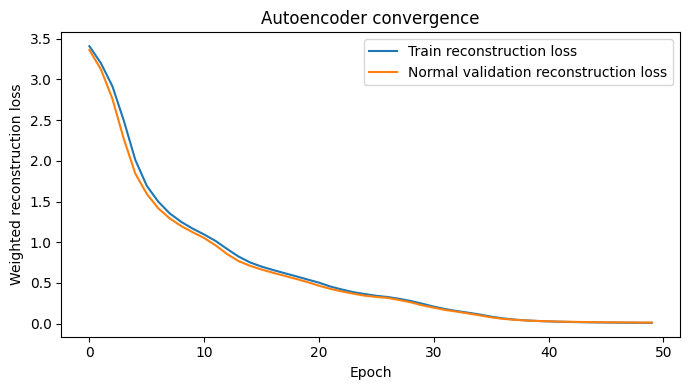

In [8]:
callback = keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
history = autoencoder.fit(ae_train_inputs, ae_train_targets,
    validation_data=(ae_val_inputs, ae_val_targets), epochs=50, batch_size=128,
    callbacks=[callback], verbose=0)
print('Training epochs:', len(history.history['loss']))
plt.figure(figsize=(7, 4))
plt.plot(history.history['loss'], label='Train reconstruction loss')
plt.plot(history.history['val_loss'], label='Normal validation reconstruction loss')
plt.xlabel('Epoch'); plt.ylabel('Weighted reconstruction loss')
plt.title('Autoencoder convergence'); plt.legend(); plt.tight_layout(); plt.show()

In [9]:
def ae_anomaly_scores(model, inputs, targets):
    predictions = model.predict(inputs, verbose=0)
    numeric_error = np.mean(np.square(targets['numeric_out'] - predictions['numeric_out']), axis=1)
    categorical_error = np.zeros(len(numeric_error), dtype='float32')
    for col in categorical_cols:
        true_idx = targets[f'{col}_out'].astype(int)
        probs = predictions[f'{col}_out']
        categorical_error += -np.log(probs[np.arange(len(true_idx)), true_idx] + 1e-8)
    categorical_error /= len(categorical_cols)
    return numeric_error + 0.35 * categorical_error

normal_val_score = ae_anomaly_scores(autoencoder, ae_val_inputs, ae_val_targets)
ae_score = ae_anomaly_scores(autoencoder, ae_test_inputs, ae_test_targets)
threshold = np.percentile(normal_val_score, 99)
ae_pred = (ae_score > threshold).astype(int)
print('AE anomaly threshold (99th percentile of normal validation):', float(threshold))
print('AE confusion matrix [TN, FP; FN, TP]:\n', confusion_matrix(y_test, ae_pred))
print(classification_report(y_test, ae_pred, target_names=['Normal','Attack']))

AE anomaly threshold (99th percentile of normal validation): 0.04272529110312462
AE confusion matrix [TN, FP; FN, TP]:
 [[754   6]
 [  0  32]]
              precision    recall  f1-score   support

      Normal       1.00      0.99      1.00       760
      Attack       0.84      1.00      0.91        32

    accuracy                           0.99       792
   macro avg       0.92      1.00      0.96       792
weighted avg       0.99      0.99      0.99       792



## 6. Quantitative comparison, agreement, and false alerts
A false positive consumes analyst time; a false negative is a missed attack. The attack-class precision, recall and F1 are reported on the same test partition. These metrics are more informative than accuracy when attacks are a minority.

In [10]:
def metric_row(name, pred):
    precision, recall, f1, _ = precision_recall_fscore_support(y_test, pred, average='binary', zero_division=0)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return dict(model=name, detected_anomalies=int(pred.sum()), precision=precision,
                recall=recall, f1=f1, false_positives=int(fp), false_negatives=int(fn),
                true_positives=int(tp), true_negatives=int(tn))
comparison = pd.DataFrame([metric_row('Isolation Forest', if_pred),
                           metric_row('Autoencoder + embeddings', ae_pred)]).set_index('model')
display(comparison.round(3))
agreement = np.mean(if_pred == ae_pred)
print(f'Agreement rate: {agreement:.2%}')
print('Both models flagged:', int(np.sum((if_pred==1) & (ae_pred==1))))
print('IF only:', int(np.sum((if_pred==1) & (ae_pred==0))))
print('AE only:', int(np.sum((if_pred==0) & (ae_pred==1))))

,detected_anomalies,precision,recall,f1,false_positives,false_negatives,true_positives,true_negatives
model,,,,,,,,
Isolation Forest,33,0.970,1.0,0.985,1,0,32,759
Autoencoder + embeddings,38,0.842,1.0,0.914,6,0,32,754


Agreement rate: 99.37%
Both models flagged: 33
IF only: 0
AE only: 5


## 7. Original feature space vs. learned latent representation

The PCA projections are diagnostic two-dimensional views: **ground truth** labels are shown in the background (`normal` circles vs. `attack` crosses), while the colored outlined markers indicate the two model alerts. It is not valid to infer superiority solely from the separation of points in 2D, because PCA discards dimensions and class imbalance can hide rare subgroups.

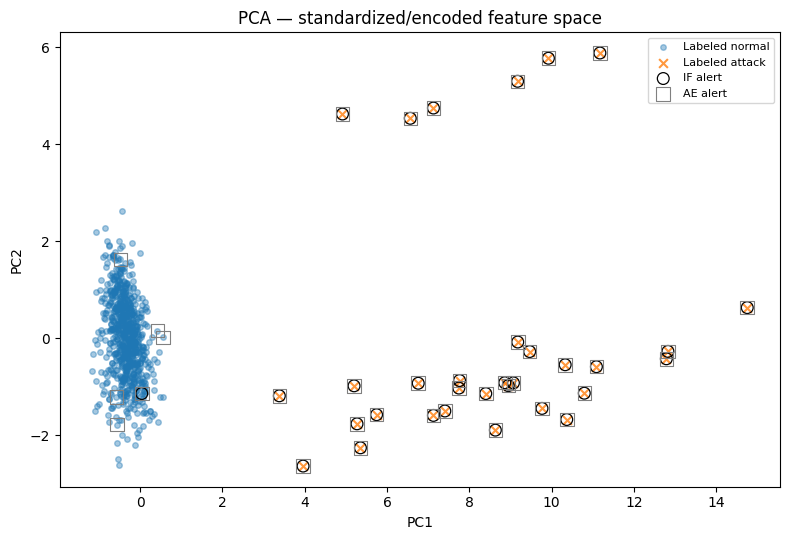

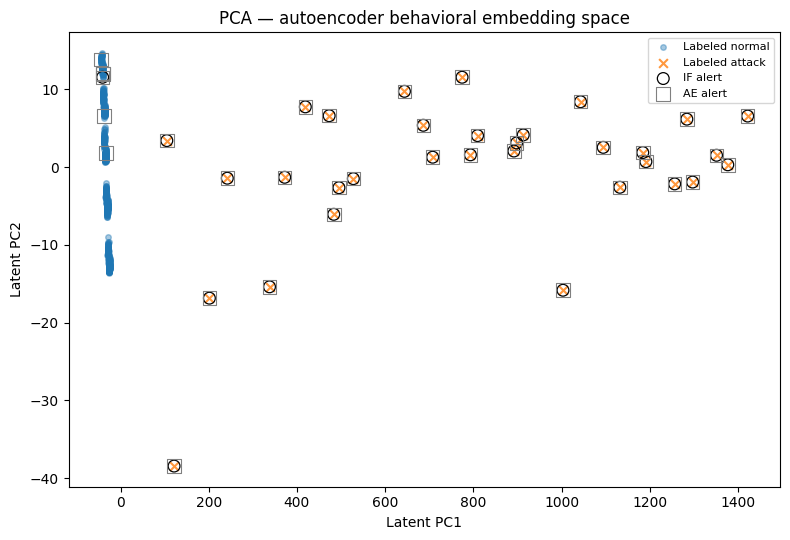

In [11]:
from matplotlib.lines import Line2D
pca_original = PCA(n_components=2, random_state=SEED)
xy_original = pca_original.fit_transform(X_if_test)
latent_vectors = encoder.predict(ae_test_inputs, verbose=0)
pca_latent = PCA(n_components=2, random_state=SEED)
xy_latent = pca_latent.fit_transform(latent_vectors)

def plot_projection(coords, title, xlab, ylab):
    plt.figure(figsize=(8, 5.5))
    normal, attack = (y_test==0), (y_test==1)
    plt.scatter(coords[normal,0], coords[normal,1], s=16, alpha=0.4, label='Labeled normal')
    plt.scatter(coords[attack,0], coords[attack,1], marker='x', s=40, alpha=0.8, label='Labeled attack')
    plt.scatter(coords[if_pred==1,0], coords[if_pred==1,1], marker='o', facecolors='none', edgecolors='black', s=72, linewidths=0.9, label='IF alert')
    plt.scatter(coords[ae_pred==1,0], coords[ae_pred==1,1], marker='s', facecolors='none', edgecolors='gray', s=95, linewidths=0.8, label='AE alert')
    plt.xlabel(xlab); plt.ylabel(ylab); plt.title(title)
    plt.legend(loc='best', fontsize=8)
    plt.tight_layout(); plt.show()
plot_projection(xy_original, 'PCA — standardized/encoded feature space', 'PC1', 'PC2')
plot_projection(xy_latent, 'PCA — autoencoder behavioral embedding space', 'Latent PC1', 'Latent PC2')

## 8. Inspect original disagreement records

A disagreement means that one model flags an event and the other does not, not that an attack was proved. For each flagged case we inspect the original record (rather than relying only on a transformed vector), model scores, predicted labels and synthetic ground truth. The scores of the two model families use different scales and should not be directly subtracted or compared in magnitude.

In [12]:
results = test_df.copy()
results['if_score'] = if_score
results['if_pred'] = if_pred
results['ae_score'] = ae_score
results['ae_pred'] = ae_pred
results['models_agree'] = results['if_pred'] == results['ae_pred']
disagreements = results[~results['models_agree']].sort_values(['ae_score','if_score'], ascending=False)
print('Disagreement count:', len(disagreements))
display(disagreements.round(4))

Disagreement count: 5


,user,country,device,protocol,hour,failed_attempts,distance_km,session_minutes,bytes_out_mb,is_attack,if_score,if_pred,ae_score,ae_pred,models_agree
870,admin01,IL,admin_workstation,VPN,16,0,4.1564,12.1581,3.9019,0,-0.0621,0,0.1408,1,False
2688,admin01,IL,admin_workstation,HTTPS,9,0,22.3629,93.2131,4.1880,0,-0.0675,0,0.0754,1,False
1525,admin01,IL,admin_workstation,HTTPS,11,0,12.0084,95.4052,17.7847,0,-0.0684,0,0.0475,1,False
2975,developer01,IL,developer_workstation,HTTPS,11,2,0.6429,23.0687,25.9308,0,-0.0918,0,0.0443,1,False
372,analyst02,IL,managed_laptop,HTTPS,10,1,31.6928,13.4944,40.4512,0,-0.1000,0,0.0438,1,False


## 9. Student SOC analyst decisions — individual case investigations

The following analysis is tied to actual event IDs and observed fields from this fixed-seed notebook run. The **CHALLENGE / VALIDATE** decision means seeking independent context before escalating or taking account actions. Every case has ground-truth label `0` in this synthetic dataset, but real SOC analysts would not possess a guaranteed label.

### 9.1 Case-by-case evaluation

#### Case 1 — record ID 870

**Model decision:** Autoencoder-only alert (IF=0, AE=1 in the saved prediction table); the score exceeds the AE threshold (0.042725). The record is labeled **normal** by the synthetic dataset.

**Original evidence:** admin01 on their usual administrative workstation in IL, using VPN at 16:00; 0 failed attempts, 12.16-minute session, 4.16 km distance and 3.90 MB outbound.

**Plausible benign explanation:** An unusually short administrative VPN session could be legitimate routine maintenance.

**SOC decision: CHALLENGE / VALIDATE.** Review VPN authentication, MFA, account ownership, device posture and approved administrative activity. Do not block or terminate the account on the model flag alone.

**MITRE ATT&CK mapping (conditional):** T1078 (Valid Accounts) only if corroborating evidence shows compromised authorized credentials.



#### Case 2 — record ID 2688

**Model decision:** Autoencoder-only alert (IF=0, AE=1 in the saved prediction table); the score exceeds the AE threshold (0.042725). The record is labeled **normal** by the synthetic dataset.

**Original evidence:** admin01, the expected workstation and IL location; HTTPS at 09:00, 0 failures, 93.21-minute session and 4.19 MB outbound.

**Plausible benign explanation:** Extended authenticated web sessions are also consistent with authorized administrative tasks.

**SOC decision: CHALLENGE / VALIDATE.** Compare user session history and authorized change windows; inspect application audit actions. Do not block or terminate the account on the model flag alone.

**MITRE ATT&CK mapping (conditional):** No supported ATT&CK technique from this record alone; T1078 is conditional on evidence of credential misuse.



#### Case 3 — record ID 1525

**Model decision:** Autoencoder-only alert (IF=0, AE=1 in the saved prediction table); the score exceeds the AE threshold (0.042725). The record is labeled **normal** by the synthetic dataset.

**Original evidence:** admin01 on the expected workstation in IL, HTTPS at 11:00, 0 failures, approximately 95.41-minute session and 17.78 MB outbound.

**Plausible benign explanation:** Longer authorized administrative work can be normal.

**SOC decision: CHALLENGE / VALIDATE.** Examine audit logs, change requests, MFA and authenticated operations. Do not block or terminate the account on the model flag alone.

**MITRE ATT&CK mapping (conditional):** No ATT&CK technique proven by these fields alone; T1078 only if compromise is corroborated.



#### Case 4 — record ID 2975

**Model decision:** Autoencoder-only alert (IF=0, AE=1 in the saved prediction table); the score exceeds the AE threshold (0.042725). The record is labeled **normal** by the synthetic dataset.

**Original evidence:** developer01 on the expected workstation in IL, HTTPS at 11:00, 2 failed attempts, 23.07-minute session and 25.93 MB outbound.

**Plausible benign explanation:** Two login failures and moderate outgoing traffic can occur in normal user workflows.

**SOC decision: CHALLENGE / VALIDATE.** Review failure reasons, session authorizations and the destination/content of the transfer. Do not block or terminate the account on the model flag alone.

**MITRE ATT&CK mapping (conditional):** T1110 requires convincing repeated password-guessing evidence; two failures alone are insufficient.



#### Case 5 — record ID 372

**Model decision:** Autoencoder-only alert (IF=0, AE=1 in the saved prediction table); the score exceeds the AE threshold (0.042725). The record is labeled **normal** by the synthetic dataset.

**Original evidence:** analyst02, managed laptop in IL, HTTPS at 10:00, 1 failed attempt, 13.49-minute session, 31.69 km distance and 40.45 MB outgoing data.

**Plausible benign explanation:** The volume is higher than the synthetic normal median, but can reflect legitimate file transfer; a single failure is not brute force.

**SOC decision: CHALLENGE / VALIDATE.** Check destination domain, file/process identity, DLP policy, business justification and authentication history. Do not block or terminate the account on the model flag alone.

**MITRE ATT&CK mapping (conditional):** T1041 (Exfiltration Over C2) is only a hypothesis if evidence of C2-linked transfer emerges; T1110 is not supported by one failure.



### 9.2 Triage synthesis

The analysis covers **at least three actual individual disagreements**, with original evidence, a plausible false-positive explanation, a human decision and a careful ATT&CK hypothesis. In this dataset the disagreement records are labeled benign; a real SOC would verify identity, authorization, endpoint telemetry, destination context and related authentication events before making the final determination. A model alert is not a confirmed security incident.



## 10. Final conclusions — all required questions

**1. Which model performed better?** On this seeded synthetic test, Isolation Forest has higher precision and F1, while both models detect all 32 labeled attacks (100% recall). See the saved quantitative comparison table and confusion matrices above. This does not imply universal superiority.

**2. Which produced fewer false positives?** Isolation Forest generated **1**, versus **6** from the autoencoder. The additional benign alerts increase SOC review workload.

**3. What anomalies were unique to each model?** The observed disagreements are **5** records. Their individual behaviors and investigative evidence are documented above; in this run they are detected only by the autoencoder. The original score and prediction tables must be used to confirm exact case counts after any rerun.

**4. Did learned embeddings help explain behavior?** The autoencoder embeds the user, country, device and protocol relationships and learns a low-dimensional latent representation. Feature-space and latent-space PCA plots are shown with the same labels and alert overlays. They help inspect patterns but do not establish greater separation or detection quality solely from a 2D plot. In this run they do not outperform IF on precision/F1.

**5. Why should an SOC analyst avoid relying on one model?** Isolation Forest isolates statistical outliers; the autoencoder measures departures from learned normal behavior. Their disagreements can reveal different sensitivities. Neither a high anomaly score nor agreement confirms an attack. Human validation must incorporate context, logs, endpoint trust and authorized user activity.

**6. What are limitations of synthetic and incomplete normal data?** This synthetic dataset makes attack events unusually distinctive (off-hour access, unknown devices/countries, high failed attempts, large distances and data volumes). Real adversaries can mimic legitimate behavior, while normal travel and maintenance can generate false alerts. The AE learns from normal-only records; IF fits a mixed training partition. Its contamination parameter also uses the observed attack prevalence, which may be unknown in production. The backend seed is explicitly set in this submission to reduce run-to-run variation; minor environment/version differences may still affect results.

**Operational recommendation:** Prefer IF as the primary triage model on this particular dataset due to fewer false alerts at equal recall. Keep the autoencoder as a complementary signal. Review disagreements individually; take potentially disruptive response actions only after corroborating evidence, not from anomaly flags alone. No automated response actions were performed in the experiment.


In [13]:
print('FINAL CHECK:', {'events': len(df), 'test_size': len(test_df),
    'if_fp': int(comparison.loc['Isolation Forest','false_positives']),
    'ae_fp': int(comparison.loc['Autoencoder + embeddings','false_positives']),
    'if_tp': int(comparison.loc['Isolation Forest','true_positives']),
    'ae_tp': int(comparison.loc['Autoencoder + embeddings','true_positives']),
    'agreements': int(np.sum(if_pred == ae_pred)),
    'disagreements': len(disagreements),
    'cases': disagreements.index.to_list(),
    'threshold': float(threshold)})

FINAL CHECK: {'events': 3960, 'test_size': 792, 'if_fp': 1, 'ae_fp': 6, 'if_tp': 32, 'ae_tp': 32, 'agreements': 787, 'disagreements': 5, 'cases': [870, 2688, 1525, 2975, 372], 'threshold': 0.04272529110312462}
